# Bank Customer Churn Prediction
**Programming for AI — Major Team Project (CUSIT, Fall 2026)**

**Team:** Talha Nadeem (16131) · Muhammad Moaz (15966) · Syed Abdullah Bin Masood (16048)

**Stakeholder:** a retail bank's customer-retention team.
**Problem:** customers who leave the bank cost revenue; the team wants to know *which* customers are at risk so it can contact them first.
**Task:** binary classification — predict `Exited` (1 = customer left, 0 = stayed) from account and demographic data.
**Intended use:** rank customers for a retention call/offer. **Not** for credit, pricing or any decision that affects a customer's access to services.

**Success criteria (measured on the held-out test set):**
1. Recall ≥ 0.65 — catch at least 65% of churners.
2. Precision ≥ 0.50 — at least half of flagged customers really churn.
3. ROC-AUC ≥ 0.85.

This notebook runs the same code as `python main.py`, step by step. All logic lives in `src/churn/` so it can be tested and reused.

In [ ]:
import sys, logging
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))   # make the project root importable

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display, Markdown

from src.churn import config
from src.churn.data_loader import load_raw_data
from src.churn.preprocessing import clean_data, split_features_target, split_train_test
from src.churn.eda import audit_dataset, data_dictionary, run_eda
from src.churn.experiments import run_all_experiments, results_table
from src.churn.evaluate import (compute_metrics, plot_confusion_matrix, fairness_report,
                                error_analysis, check_success_criteria)
from src.churn.models import MODEL_LABELS
from src.churn.predict import predict_churn

logging.basicConfig(level=logging.INFO, format="%(message)s")
logging.getLogger("matplotlib").setLevel(logging.WARNING)
config.ensure_output_dirs()
pd.set_option("display.max_columns", 30)
print("Random seed:", config.RANDOM_STATE)

Random seed: 42


## 1. Load and validate the data
`load_raw_data` checks the file exists, is a non-empty CSV and has every required column.

In [ ]:
raw = load_raw_data()
raw.head()

Loaded 10000 rows x 14 columns from Churn_Modelling.csv


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## 2. Dataset audit and data dictionary

In [ ]:
audit = audit_dataset(raw)
{k: v for k, v in audit.items() if k != 'missing_by_column'}

{'rows': 10000,
 'columns': 14,
 'missing_values_total': 0,
 'duplicate_rows': 0,
 'duplicate_customer_ids': 0,
 'stayed': 7963,
 'churned': 2037,
 'churn_rate': 0.2037,
 'zero_balance_share': 0.3617,
 'personal_data_columns': ['Surname', 'CustomerId']}

In [ ]:
data_dictionary(raw)

,column,dtype,role,description,values,missing
0,RowNumber,int64,identifier (dropped),"Row index in the original file (identifier, re...",1 to 10000,0
1,CustomerId,int64,identifier (dropped),"Bank customer ID (identifier, removed for priv...",1.55657e+07 to 1.58157e+07,0
2,Surname,str,identifier (dropped),"Customer surname (personal data, removed for p...","2932 unique: Hargrave, Hill, Onio, Boni, Mitch...",0
3,CreditScore,int64,feature,Customer credit score.,350 to 850,0
4,Geography,str,feature,"Country of the customer (France, Germany, Spain).","3 unique: France, Spain, Germany",0
5,Gender,str,feature,Customer gender as recorded by the bank (Male/...,"2 unique: Female, Male",0
6,Age,int64,feature,Customer age in years.,18 to 92,0
7,Tenure,int64,feature,Number of years the customer has been with the...,0 to 10,0
8,Balance,float64,feature,Account balance (currency not stated in the so...,0 to 250898,0
9,NumOfProducts,int64,feature,Number of bank products the customer uses.,1 to 4,0


**Audit notes**
- No missing values, duplicate rows or duplicate customer IDs.
- Imbalanced target: about 20% churn.
- `Surname` and `CustomerId` are personal data and are removed. They carry no legitimate predictive meaning.
- 36% of customers have a zero balance. This is a real value, not missing data.

## 3. Cleaning
Each step and its justification is documented in `clean_data`. Unlike the original notebook, numeric columns keep their decimals (no `.astype(int)`).

In [ ]:
clean, cleaning_report = clean_data(raw)
print(cleaning_report)
clean.head()

Cleaning report: {'rows_in': 10000, 'id_columns_dropped': 3, 'rows_missing_target': 0, 'duplicate_rows': 0, 'invalid_rows': 0, 'missing_feature_values': 0, 'rows_out': 10000}


{'rows_in': 10000, 'id_columns_dropped': 3, 'rows_missing_target': 0, 'duplicate_rows': 0, 'invalid_rows': 0, 'missing_feature_values': 0, 'rows_out': 10000}


,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## 4. Exploratory data analysis (Matplotlib)
Each chart is saved to `outputs/figures/`, and its interpretation is computed from the data.

Saved eda_01_class_balance.png


Saved eda_02_age_by_churn.png


Saved eda_03_churn_by_products.png


Saved eda_04_churn_by_geography_gender.png


Saved eda_05_activity_balance.png


Saved eda_06_correlation_matrix.png


Saved eda_07_numeric_boxplots.png


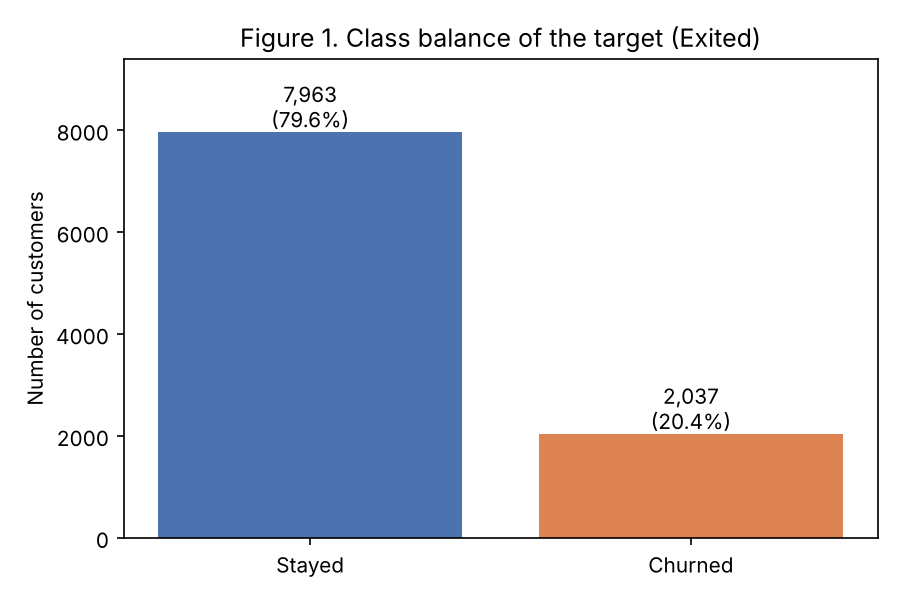

**Interpretation:** Only 20.4% of customers churned, so the classes are imbalanced. A model that always predicts 'stays' would already be 79.6% accurate, which is why accuracy alone is misleading and recall/F1 are used to judge models.

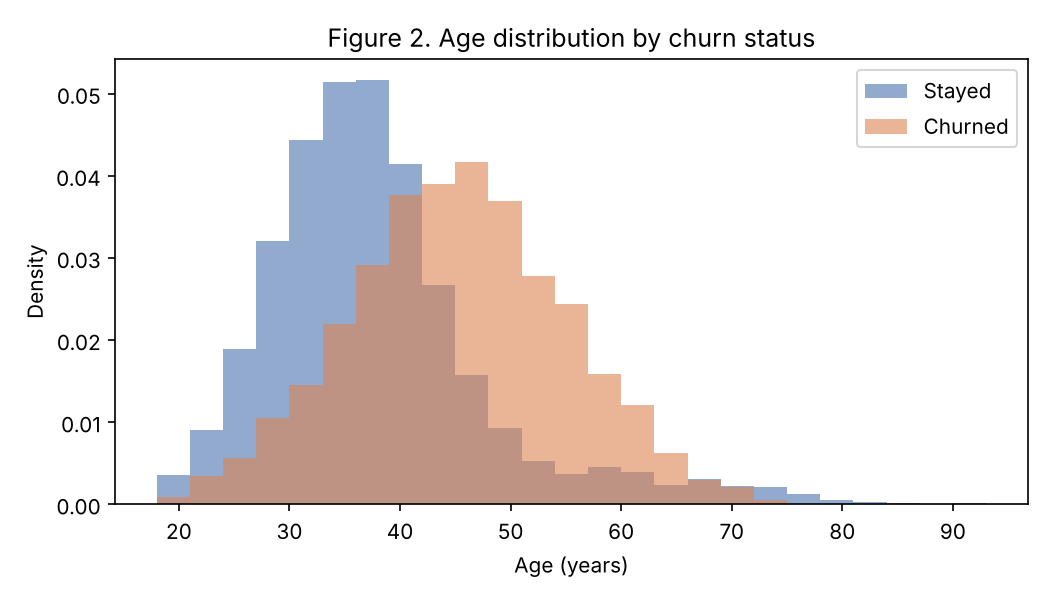

**Interpretation:** Churned customers are older (median age 45 vs 36). Churn peaks at 56.0% for ages 50-59 compared with 7.6% for under-30s, so Age is one of the strongest predictors.

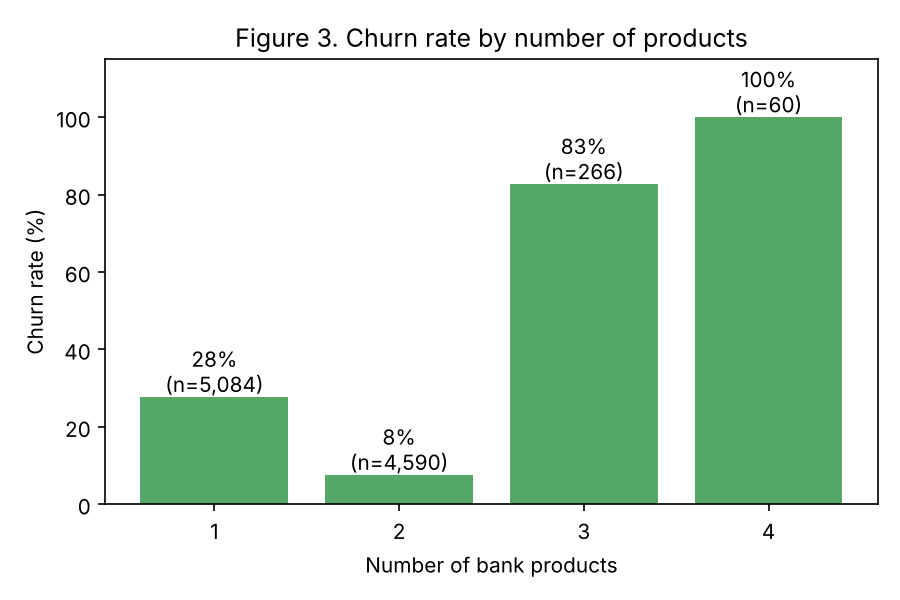

**Interpretation:** The relationship is not linear: customers with 2 products churn least (7.6%), 1 product is 27.7%, while 3 products (82.7%) and 4 products (100.0%, only 60 customers) almost always churn. Tree-based models can capture this non-linear pattern better than logistic regression.

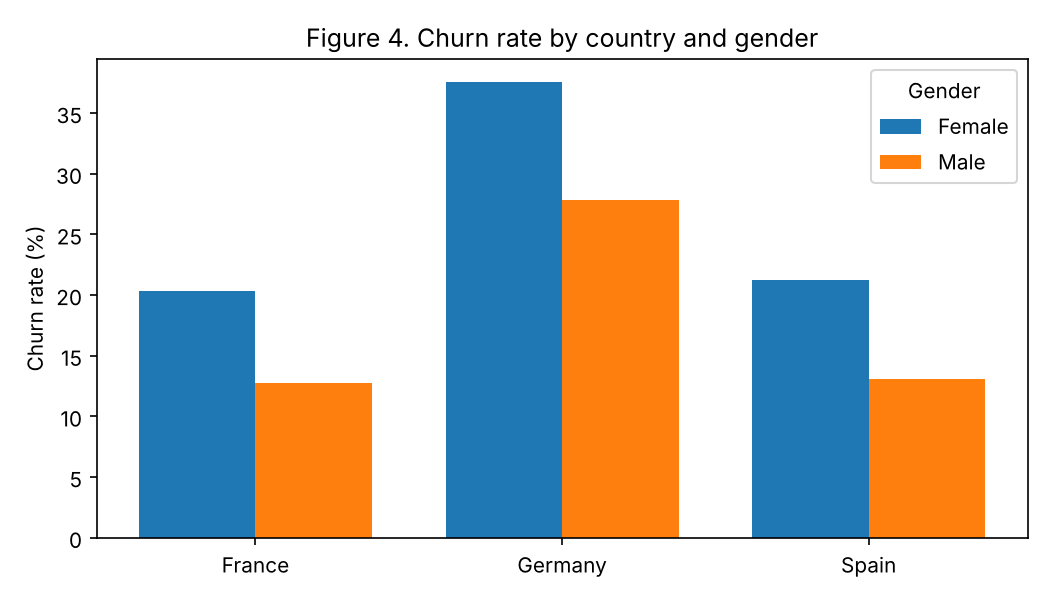

**Interpretation:** Germany has the highest churn (32.4%) versus France (16.2%) and Spain (16.7%). Female customers churn more (25.1%) than male customers (16.5%) in every country. These are sensitive attributes, so the model's errors are checked per group in the fairness analysis.

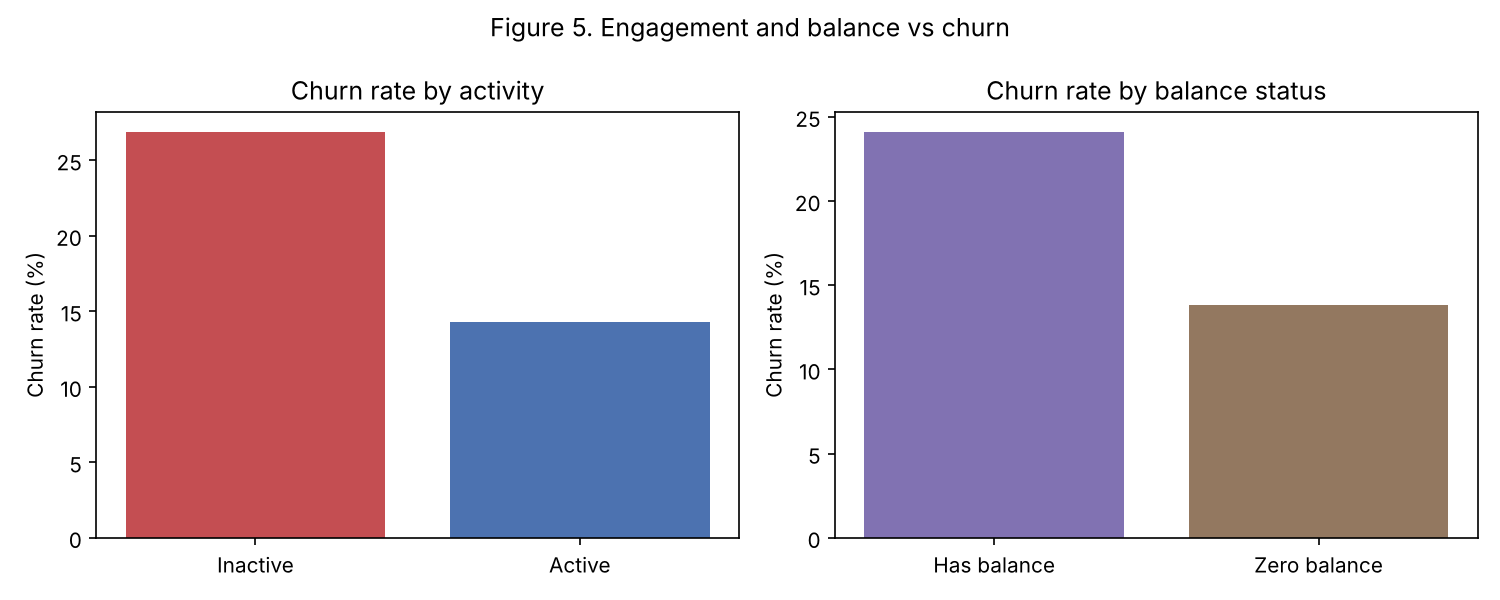

**Interpretation:** Inactive members churn at 26.9% compared with 14.3% for active members. Customers holding a balance churn at 24.1% vs 13.8% for zero-balance customers, which motivates the engineered HasZeroBalance feature.

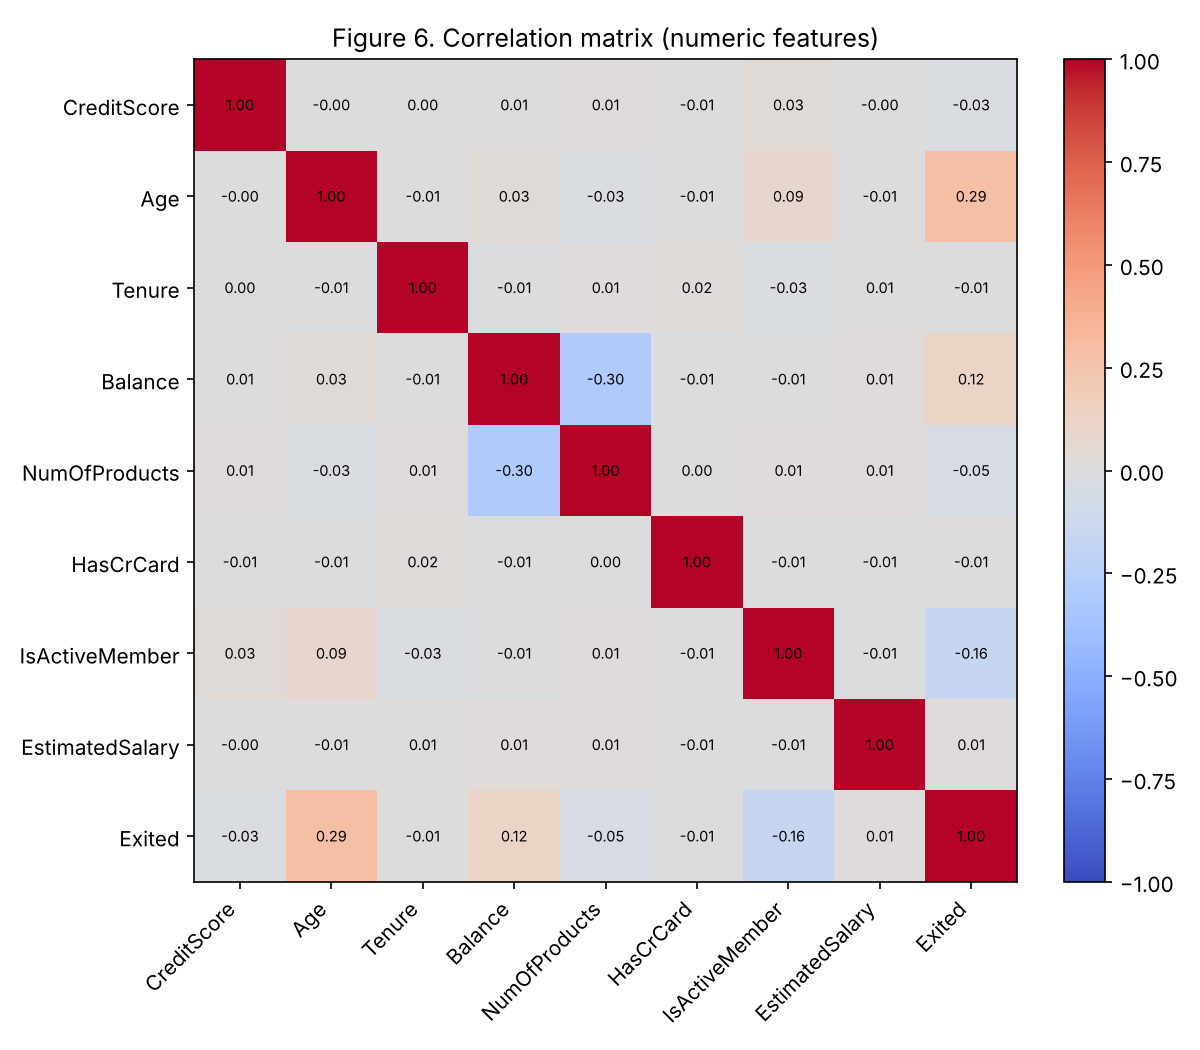

**Interpretation:** Strongest linear links with churn: Age (+0.29), IsActiveMember (-0.16), Balance (+0.12). Weakest: Tenure (-0.01), EstimatedSalary (+0.01), HasCrCard (-0.01). No two input features are strongly correlated (largest |r| = 0.30), so multicollinearity is not a concern. Weak linear correlation does not rule out non-linear effects (e.g. NumOfProducts).

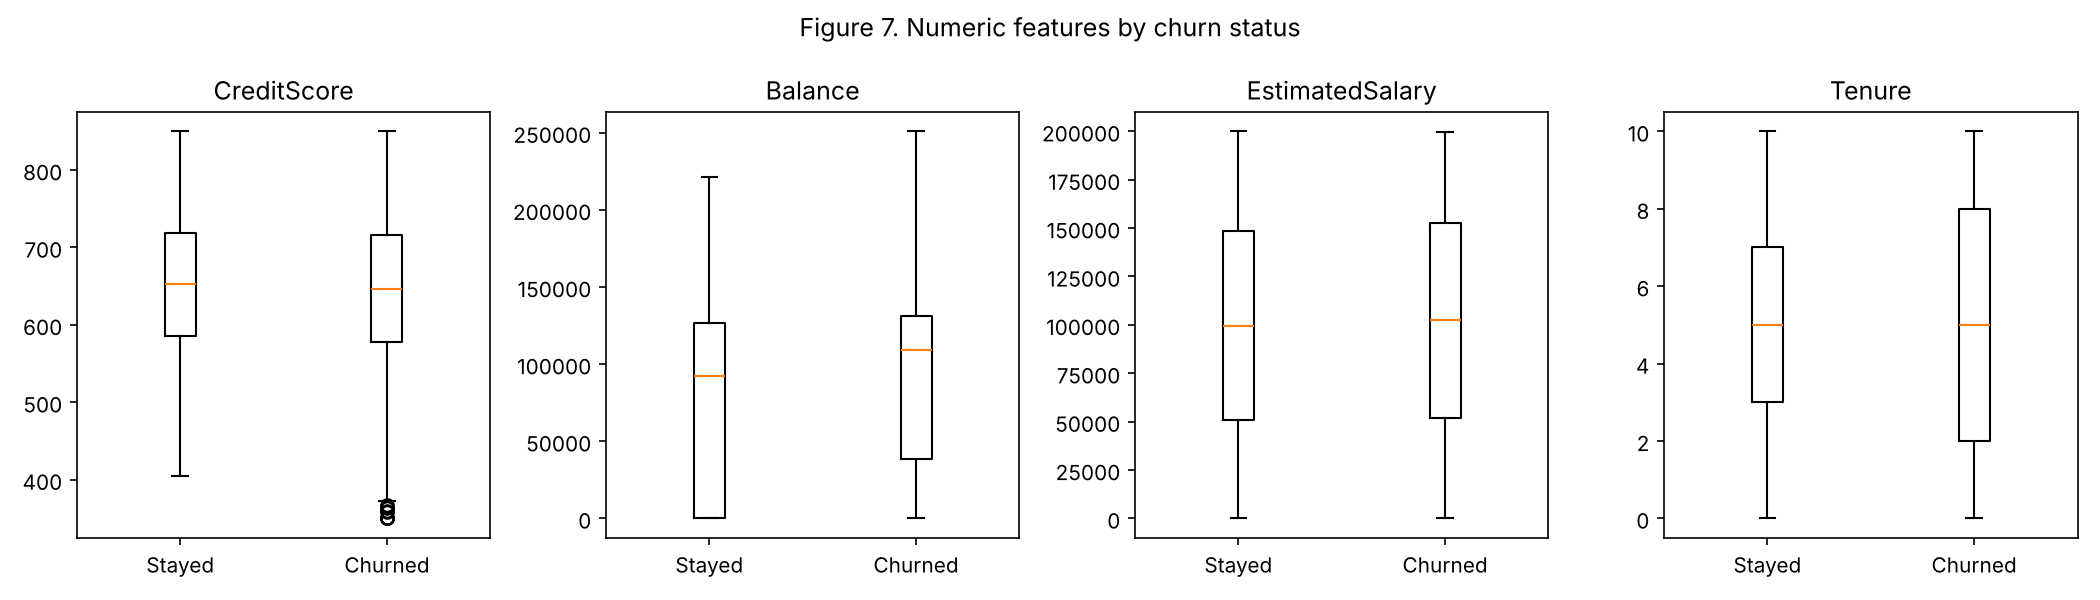

**Interpretation:** CreditScore: median 653 (stayed) vs 646 (churned); Balance: median 92,073 (stayed) vs 109,349 (churned); EstimatedSalary: median 99,645 (stayed) vs 102,461 (churned); Tenure: median 5 (stayed) vs 5 (churned). CreditScore, EstimatedSalary and Tenure barely differ between the groups, which supports testing a model without the weakest features in the feature-selection experiment.

In [ ]:
findings = run_eda(clean)
for f in findings:
    display(Image(filename=str(config.FIGURES_DIR / f["figure"]), width=650))
    display(Markdown("**Interpretation:** " + f["finding"]))

## 5. Features, target and train/test strategy
- **Target:** `Exited`. **Features:** 8 numeric and 2 categorical (identifiers removed).
- **Split:** 80/20, **stratified** so both sets keep the ~20% churn rate. Fixed seed.
- **No leakage:** imputation, scaling and one-hot encoding sit inside a scikit-learn `Pipeline` and are fitted on the training data only (refitted inside every CV fold).
- **Model selection:** 5-fold stratified cross-validation on the training set. The test set is used only for the final report.

In [ ]:
X, y = split_features_target(clean)
X_train, X_test, y_train, y_test = split_train_test(X, y)
print(f"Train: {X_train.shape}, churn rate {y_train.mean():.3f}")
print(f"Test : {X_test.shape}, churn rate {y_test.mean():.3f}")

Train: (8000, 10), churn rate 0.204
Test : (2000, 10), churn rate 0.203


## 6. Experiments
| Run | What changes |
|---|---|
| E1 | **Baseline:** logistic regression, default settings |
| E2 | Class imbalance handled with `class_weight='balanced'` |
| E3a–c | Model comparison: Random Forest, Gradient Boosting, **MLP neural network (ANN)** |
| E4a–c | Feature changes on the best E3 model: engineered features, dropping weak features, both |
| E5 | Grid-search tuning + decision-threshold tuning (maximise recall with precision ≥ 0.55 on out-of-fold training predictions) |

The full grid search takes a few minutes.

In [ ]:
exp = run_all_experiments(X_train, y_train, X_test, y_test, quick=False)
table = results_table(exp["results"])
cols = ["run_id", "model", "description", "cv_f1", "test_accuracy", "test_precision",
        "test_recall", "test_f1", "test_roc_auc"]
table[cols].round(3)

E1   Logistic Regression          CV F1=0.315  test F1=0.284  recall=0.187


E2   Logistic Regression          CV F1=0.489  test F1=0.499  recall=0.700


E3a  Random Forest                CV F1=0.604  test F1=0.596  recall=0.582


E3b  Gradient Boosting            CV F1=0.602  test F1=0.591  recall=0.624


E3c  MLP Neural Network (ANN)     CV F1=0.561  test F1=0.610  recall=0.516


E4a  Random Forest                CV F1=0.605  test F1=0.618  recall=0.622


E4b  Random Forest                CV F1=0.599  test F1=0.588  recall=0.612


E4c  Random Forest                CV F1=0.602  test F1=0.597  recall=0.614


,run_id,model,description,cv_f1,test_accuracy,test_precision,test_recall,test_f1,test_roc_auc
0,E1,Logistic Regression,"Logistic regression, all original features, de...",0.315,0.808,0.589,0.187,0.284,0.775
1,E2,Logistic Regression,Same as E1 but class_weight='balanced' so miss...,0.489,0.714,0.387,0.700,0.499,0.777
2,E3a,Random Forest,"Random forest (300 trees), balanced class weights",0.604,0.840,0.611,0.582,0.596,0.851
3,E3b,Gradient Boosting,"Histogram gradient boosting, balanced class we...",0.602,0.824,0.561,0.624,0.591,0.843
4,E3c,MLP Neural Network (ANN),"MLP neural network (3 x 11 ReLU, same as origi...",0.561,0.866,0.745,0.516,0.610,0.863
5,E4a,Random Forest,Best E3 model + 4 engineered features,0.605,0.844,0.614,0.622,0.618,0.851
6,E4b,Random Forest,Best E3 model without weak features (HasCrCard...,0.599,0.826,0.566,0.612,0.588,0.836
7,E4c,Random Forest,Best E3 model + engineered features - weak fea...,0.602,0.831,0.580,0.614,0.597,0.846
8,E5,Random Forest,Grid-searched hyper-parameters + tuned decisio...,0.609,0.832,0.572,0.681,0.622,0.859


In [ ]:
for d in exp['decisions']:
    print('-', d)

- E2 vs E1: balancing class weights changed CV recall from 0.214 to 0.686 and CV F1 from 0.315 to 0.489.
- E3: best model family by CV F1 is Random Forest (CV F1 0.604).
- E4: best feature set by CV F1 is run E4a (engineered=True, dropped=none, CV F1 0.605).
- E5: grid search tried 36 combinations x 5 folds; best CV F1 0.615 with {'class_weight': 'balanced_subsample', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 5}.
- E5: threshold tuned on out-of-fold training predictions to maximise recall with precision >= 0.55 -> 0.45 (OOF F1 0.609, recall 0.675, precision 0.555).
- E5 vs E4a: tuning changed CV F1 (threshold 0.5) from 0.605 to 0.615; at the tuned threshold the OOF recall is 0.675. (E5's cv_* columns are out-of-fold scores at the tuned threshold.)
- FINAL MODEL: Random Forest (run E5), threshold 0.45. Selected on cross-validated training performance only; test set used once for the final report.


**Why recall and F1 matter most here.** Only 20% of customers churn, so a model that predicts "stays" for everyone is about 80% accurate and useless. A missed churner (false negative) costs the bank a customer. A false alarm (false positive) only costs a retention call. So **recall** is the priority, with **precision** kept high enough that the team's effort isn't wasted. F1 balances the two.

## 7. Final model on the held-out test set

In [ ]:
final, t = exp["final"], exp["threshold"]
baseline = exp["results"][0]
comparison = pd.DataFrame({
    "Baseline E1 (t=0.50)": baseline.test_metrics,
    "Final E5 (t=0.50)": compute_metrics(y_test, final.test_proba, 0.5),
    f"Final E5 (tuned t={t:.2f})": final.test_metrics,
}).loc[["accuracy", "precision", "recall", "f1", "roc_auc", "pr_auc", "tp", "fn", "fp", "tn"]]
print("Final model:", MODEL_LABELS[final.spec.model_name], final.spec.model_params)
comparison.round(3)

Final model: Random Forest {'class_weight': 'balanced_subsample', 'max_depth': None, 'max_features': 'sqrt', 'min_samples_leaf': 5}


,Baseline E1 (t=0.50),Final E5 (t=0.50),Final E5 (tuned t=0.45)
accuracy,0.808,0.848,0.832
precision,0.589,0.625,0.572
recall,0.187,0.634,0.681
f1,0.284,0.629,0.622
roc_auc,0.775,0.859,0.859
pr_auc,0.479,0.700,0.700
tp,76.000,258.000,277.000
fn,331.000,149.000,130.000
fp,53.000,155.000,207.000
tn,1540.000,1438.000,1386.000


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, m) in zip(axes, [("Baseline E1", baseline.test_metrics), (f"Final E5 (t={t:.2f})", final.test_metrics)]):
    cm = np.array([[m["tn"], m["fp"]], [m["fn"], m["tp"]]])
    ax.imshow(cm, cmap="Blues")
    for i in range(2):
        for j in range(2):
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=14,
                    color="white" if cm[i, j] > cm.max() / 2 else "black")
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Pred: stay", "Pred: churn"])
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Actual: stayed", "Actual: churned"])
    ax.set_title(name)
fig.suptitle("Confusion matrices on the test set")
plt.tight_layout(); plt.show()

In [ ]:
criteria = check_success_criteria(final.test_metrics, config.SUCCESS_CRITERIA)
criteria

,criterion,metric,target,achieved,met
0,Catch at least 65% of customers who actually c...,recall,0.65,0.681,True
1,At least half of the customers flagged really ...,precision,0.50,0.572,True
2,Rank churners above non-churners well (ROC-AUC),roc_auc,0.85,0.859,True


## 8. Fairness and error analysis

In [ ]:
y_pred = (final.test_proba >= t).astype(int)
fairness_report(X_test, y_test, y_pred).round(3)

,attribute,group,n,actual_churn_rate,predicted_churn_rate,recall,precision,false_positive_rate,f1
0,Gender,Female,930,0.251,0.301,0.704,0.586,0.166,0.639
1,Gender,Male,1070,0.163,0.191,0.649,0.554,0.102,0.598
2,Geography,France,1021,0.171,0.181,0.583,0.551,0.098,0.567
3,Geography,Germany,504,0.300,0.423,0.815,0.577,0.255,0.676
4,Geography,Spain,475,0.171,0.181,0.642,0.605,0.086,0.623


In [ ]:
error_analysis(X_test, y_test, y_pred)

,count,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,is_germany,is_female
outcome,,,,,,,,,,,
FN (missed churner),130,652.29,39.18,4.98,87449.20,1.41,0.68,0.42,94360.54,0.22,0.53
FP (false alarm),207,643.98,44.72,5.14,91207.94,1.26,0.71,0.46,105945.30,0.43,0.56
TN (correct stay),1386,650.45,36.11,5.08,70866.42,1.58,0.68,0.57,101546.62,0.19,0.42
TP (caught churner),277,648.51,47.83,4.50,91479.91,1.56,0.73,0.31,101497.27,0.44,0.59


**How to read this**
- Compare recall and false-positive rate across groups. A higher false-positive rate for a group means its customers are flagged more often without churning.
- The FN row shows which churners the model misses. Compare its averages with the TP row.
- See `outputs/results/run_summary.md` for the full interpretation.

## 9. Demo: scoring new (unseen) customers
These are real customers from the held-out test set, with no identifiers and no target. Invalid input (e.g. an unknown country) raises a clear error.

In [ ]:
new_customers = X_test.head(10)
predict_churn(new_customers, final.pipeline, threshold=t)[
    ["Geography", "Gender", "Age", "NumOfProducts", "IsActiveMember", "Balance",
     "churn_probability", "predicted_churn", "risk_band"]]

,Geography,Gender,Age,NumOfProducts,IsActiveMember,Balance,churn_probability,predicted_churn,risk_band
5702,France,Male,36,2,0,0.00,0.021,0,Low
3667,Germany,Male,33,2,0,131023.76,0.068,0,Low
1617,Spain,Female,40,2,1,0.00,0.090,0,Low
5673,Spain,Male,34,2,0,139393.19,0.084,0,Low
4272,Spain,Female,34,1,1,77826.80,0.277,0,Low
8270,Spain,Male,34,1,0,0.00,0.402,0,Medium
7079,Germany,Male,30,2,1,130682.11,0.062,0,Low
5295,Germany,Female,29,1,0,185544.36,0.293,0,Low
845,France,Male,49,1,0,80001.23,0.623,1,High
5311,France,Female,40,2,0,0.00,0.168,0,Low


In [ ]:
bad = new_customers.head(1).copy()
bad["Geography"] = "Italy"
try:
    predict_churn(bad, final.pipeline, threshold=t)
except Exception as exc:
    print(type(exc).__name__, "->", exc)

DataValidationError -> 1 invalid value(s) found in the input:
 row    column value                                   problem
5702 Geography Italy not one of ['France', 'Germany', 'Spain']


## 10. Recommendation and limitations (summary)
- **Use:** a weekly ranked list of customers at High/Medium risk for the retention team to contact.
- **Do not use:** to deny services, set prices, or make any automated decision about a customer.
- **Limitations:** a single public dataset with no date range or named bank, and only 3 countries. Gender and Geography are used as features (fairness risk). The 4-product group has only 60 customers.
- **Before any real use:** validate on the bank's own recent data, monitor for drift, review fairness with compliance, and run an A/B test of retention actions.